# Brain MRI image based disease classification 🧠

A simle neural network model for disease classification from MRI scan image, Exploring building image based nural network pipeline with torch, Feeding nerual network with stream of tensors from image dataset, simple preprocessing pipeline with data loader component from torch utility functions.

## Dataset and problem breif

Dataset contains vast images perticularly classified for each of the disease part, with image names we can disect them into rich set of information and build something really powerfull,Images name contains more informative sub parts of the problem with which we can attempt for making more sophesticated research directives with images,

## Project spectrum

Current scope is purely aimed for exploration of idea with deep learning with real machine learning dataset, with strong proff and strong domain knowledge about each descease and its label context, i would love to talk with real doctors to help them use this as a tool for their treatment and get on ground insights about the model with interviewing a real brain doctor, 
Approach binary classification for abnormality detection

In [14]:
import pandas as pd
from pathlib import Path
import numpy as np

# dataset preapration
''' 
Mixing fixed set of normal brain MRI
with disease based dataset.
''' 
target_dir = Path('/home/madhav/workstation/Lab/experiment/data/BrainMRI')
# dataset annotation sheet

dataset = []
for item in target_dir.iterdir():
    label = (item.name).lower()
    for image in item.iterdir():
        path = image.resolve() # absolute path
        dataset.append({
            'image_path': path,
            'label' : label
        })
df = pd.DataFrame(dataset)

# Preparing Dataset

root_grouping = df[
    df['label'] == 'normal'
].copy(deep=True)

abnormals = df[
    df['label'] != 'normal'
].sample(100).copy(deep=True)

'''
With updating the label through
df[condition] = abnormal
would make every string replace with out normal word
thus we need to specify the edit with the df

Also raises internal chain assignment error through pandas, 
for alternate representation guide
'''

dataset = pd.concat([root_grouping, abnormals], axis=0, ignore_index=True)
dataset.loc[
    dataset['label'] != 'normal', 'label'
] = 'abnormal'  # Better way with locking up targets locations with loc api

# Train Test separation for data loader functions with torch
from sklearn.model_selection import train_test_split

dataset.reset_index(drop=True, inplace=True)

dataset.loc[
    dataset['label'] == 'normal', 'label'
] = '0'

dataset.loc[
    dataset['label'] == 'abnormal', 'label'
] = '1'

dataset['label'] = pd.to_numeric(dataset['label'])

train_df, test_df = train_test_split(dataset, test_size=0.2, random_state=42)

train_df

,image_path,label
183,/home/madhav/workstation/Lab/experiment/data/B...,1
38,/home/madhav/workstation/Lab/experiment/data/B...,0
24,/home/madhav/workstation/Lab/experiment/data/B...,0
142,/home/madhav/workstation/Lab/experiment/data/B...,1
141,/home/madhav/workstation/Lab/experiment/data/B...,1
...,...,...
106,/home/madhav/workstation/Lab/experiment/data/B...,1
14,/home/madhav/workstation/Lab/experiment/data/B...,0
92,/home/madhav/workstation/Lab/experiment/data/B...,0
179,/home/madhav/workstation/Lab/experiment/data/B...,1


## Image plot context

Image formation with [channel, height, width ] is the representation of image with 3 layer of colourization with each layer consisting red blue and green pixel information, since one pixel is formed with combination of these 3 we have a  3 set of pixel grid information to represent a image into the plot <br>

Torch and matplotlib conflicts with image representation ways, with matplotlib taking channel at last, torch elements taking channels at the first indexing, thus we need to transpose for changing the position of the information for making plots.

In [15]:
# image transformer
import torchvision.transforms.v2 as transforms

transformer = transforms.Compose([
    transforms.RandomResizedCrop(size=(224,224), antialias=True),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(contrast=0.5)
])

Simple load : torch.Size([3, 224, 224]), with transposed image : (224, 224, 3)


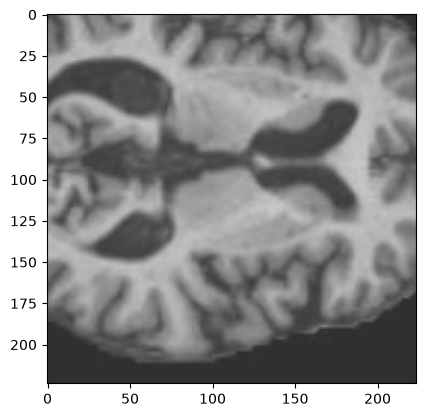

In [16]:
# Simple visualization of random image form the dataset
import torchvision.io as tv_io
import matplotlib.pyplot as plt
import numpy as np
from torchvision.io import ImageReadMode


# loading with tv io based loading pipeline

path = '/home/madhav/workstation/Lab/experiment/data/BrainMRI/Alzheimer/mildDem300.jpg'
raw_image = tv_io.read_file(path)
img_tensor = tv_io.decode_image(raw_image, mode=ImageReadMode.RGB)

img_nums = transformer(img_tensor)

plot_nums = img_nums.cpu().numpy().transpose(2,1,0)

print(f'Simple load : {img_nums.shape}, with transposed image : {plot_nums.shape}')

# Loding image plot with matplotlib | transposing the actual tensor dataset

plt.imshow(plot_nums)


In [17]:
# Torch custom data loader instance
import torch
from torch.utils.data import Dataset, DataLoader

import torchvision.io as tv_io
from torchvision.io import ImageReadMode

class ImageDataset(Dataset):
    ''' 
    Simple image dataset object handle,
    Loading dataset through iamges pathways
    ''' 

    def __init__(self, dataframe, transform):
        
        self.image_paths = dataframe['image_path']
        self.labels = dataframe['label']
        self.transform = transform
    
    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths.iloc[idx,]
        raw_nums = tv_io.decode_image(path, ImageReadMode.RGB)
        transformed_tensor = self.transform(raw_nums)
        transformed_tensor = torch.flatten(transformed_tensor)
        print(transformed_tensor.shape)
        
        return transformed_tensor, self.labels.iloc[idx,]

# Train and validation dataset
train_dataset = ImageDataset(train_df, transformer)
test_dataset = ImageDataset(test_df, transformer)

# Data Loader elements
train_loader = DataLoader(train_dataset, batch_size=10, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=10, shuffle=True)

for _ in train_loader:
    print(_)

torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
[tensor([[ 28,  28,  28,  ..., 132, 138, 142],
        [  5,   6,   7,  ...,   4,   4,   4],
        [  7,   7,   7,  ...,   7,   7,   7],
        ...,
        [  0,   0,   0,  ...,   0,   0,   0],
        [255, 255, 255,  ...,  82,  82,  82],
        [  0,   0,   0,  ...,   0,   0,   0]], dtype=torch.uint8), tensor([1, 1, 0, 1, 0, 1, 0, 0, 0, 0])]
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
torch.Size([150528])
[tensor([[ 0,  0,  0,  ...,  0,  0,  0],
        [14, 14, 14,  ...,  2,  2,  2],
        [ 4,  4,  4,  ...,  4,  4,  4],
        ...,
        [ 0,  0,  0,  ...,  0,  0,  0],
        [15, 15, 15,  ..., 15, 15, 14],
        [13, 13

In [18]:
# Multilayer perceptron model with torch framework
import torch
import torch.nn as nn 
import torch.nn.functional as F

class MRIModel(nn.Module):
    ''' 
    Multilayer-perceptron for brain mri dataset
    Architechture
    - input : flatened tensor input
    - Hidden layer : ReLu activation for non-linearity
    - Output : 2 class (softmax applied in loss function)

    Potential crashout due to massive input layer requirement with image processing
    need to upgrade with pca based preprcessing with the dataset
    ''' 
    def __init__(self, input_size=150528, hidden1_size=128, hidden2_size=128, num_classes=1):
        super(MRIModel, self).__init__()

        # Nework layers
        self.flatten = nn.Flatten() # one dimension

        self.hidden1 = nn.Linear(input_size, hidden1_size)
        self.hidden2 = nn.Linear(hidden1_size, hidden2_size)
        self.output = nn.Linear(hidden2_size, num_classes)

        self.relu = nn.ReLU() # applied between the layers
        self.dropout = nn.Dropout(p=0.2) # what does this mean ?

        # Load architechture
        self.architecht_info = {
            'input_size':input_size, 
            'hidden_layer_1':hidden1_size,
            'hidden_layer_2': hidden2_size
        }

    def forward(self, x):
        ''' 
        Forward pass through the network
        Args:
            x : input tensor of shape simple flattened tensor
        '''
        x = self.flatten(x)
        
        # Layers penetration
        x = self.hidden1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.hidden2(x)
        x = self.relu(x)
        x = self.dropout(x)

        # Output Layer
        logits = sel
        f.output(x)
        
        return logits

    def get_model_info(self):
        return self.architecht_info


device = 'cuda'
model = MRIModel().to(device)
print(model)

# Testing forward pass with sample batch
with torch.no_grad():
    img_nums = img_nums.to(device)
    print(type(img_nums))
    sample_input = img_nums
    output = model(sample_input)
    prob = F.softmax(output, dim=1)

MRIModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden1): Linear(in_features=150528, out_features=128, bias=True)
  (hidden2): Linear(in_features=128, out_features=128, bias=True)
  (output): Linear(in_features=128, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)
<class 'torch.Tensor'>


RuntimeError: mat1 and mat2 must have the same dtype, but got Byte and Float